# Predicting newborn birth weight from maternity register data

## Mission and use case
**Mission:** reduce preventable maternal and newborn deaths by helping health facilities spot high-risk births early.

**Use case:** estimate a newborn's **birth weight (kg)** from information that is on the maternity register at delivery: gestational age, mother's age, plurality (singleton/twins/...), baby's sex, mode of delivery, viability, country and facility.

**Who uses it and for what:**
- *Midwives and clinicians* get an expected weight to flag likely **low birth weight (< 2.5 kg)** babies and prepare neonatal care early.
- *Facility managers and data teams* compare the expected weight with the recorded one to catch **data-entry errors** (a 10 kg baby, a 150 g live birth) in registers.

**Dataset:** a de-identified maternity register from facilities in Uganda and Kenya (PTBi maternity register). One row is one delivery.
**Target:** `birth_weight` in grams, converted to kilograms (a continuous number).

In [3]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load and clean the data

In [4]:
raw = pd.read_excel("maternity_register.xlsx")
print("Raw shape:", raw.shape)

df = raw.replace(r"^\s*$", np.nan, regex=True)          # blank cells are stored as ' '
df = df.rename(columns={"ga (rec)": "ga_weeks", "birth_weight": "birth_weight_g"})
for c in ["ga_weeks", "birth_weight_g", "mothers_age"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Merge spelling variants and group the very rare delivery modes
df["mode_of_delivery"] = df["mode_of_delivery"].str.replace("BREECH", "Breech", case=False)
common = ["Normal_Vaginal_Delivery", "Caesarean_Section", "Born_Before_Arrival"]
df["mode_of_delivery"] = df["mode_of_delivery"].where(df["mode_of_delivery"].isin(common) | df["mode_of_delivery"].isna(), "Other")

# Keep rows with a recorded and physically plausible weight (0.5 - 6 kg)
before = len(df)
df = df[df["birth_weight_g"].between(500, 6000)].copy()
df["birth_weight_kg"] = df["birth_weight_g"] / 1000
print(f"Rows kept: {len(df):,} of {before:,} (dropped {before-len(df):,} with missing or implausible weight)")
df.head()

Raw shape: (19219, 17)
Rows kept: 17,180 of 19,219 (dropped 2,039 with missing or implausible weight)


,facility_birth,ga_weeks,ga (calc),mode_of_delivery,birth_outcome,birth_weight_g,baby_delivery_status,mother_discharge_status,baby_discharge_status,eligibility_for_ptbi,eligible_for_followup,sex,country,viability,mothers_age,multiple,facility,birth_weight_kg
2022,Facility birth,38.0,37.714286,Normal_Vaginal_Delivery,Live_Birth,6000.0,Live_Birth,NaN,Live baby,Eligible,Ineligible for Follow-up,Male,Kenya,No Indication,34.0,1,Isebania_Sub-County_Hospital,6.0
2023,Facility birth,NaN,NaN,Caesarean_Section,Live_Birth,5700.0,NaN,NaN,Live baby,Eligible,Ineligible for Follow-up,Male,Uganda,No Indication,37.0,1,Jinja_Regional_Ref_Hospital,5.7
2024,Facility birth,40.0,NaN,Caesarean_Section,Live_Birth,5700.0,NaN,Discharged_Alive,Live baby,Eligible,Ineligible for Follow-up,Male,Uganda,No Indication,30.0,1,Buluba_Hospital,5.7
2025,Facility birth,38.0,NaN,Caesarean_Section,Live_Birth,5700.0,NaN,Discharged_Alive,Live baby,Eligible,Ineligible for Follow-up,Female,Uganda,No Indication,41.0,1,Kamuli_Mission_Hospital,5.7
2026,Facility birth,40.0,38.857143,Normal_Vaginal_Delivery,Live_Birth,5500.0,Live_Birth,NaN,Live baby,Eligible,Ineligible for Follow-up,Female,Kenya,No Indication,22.0,1,Ntimaru_Sub-County_Hospital,5.5


## 2. Dataset overview

In [5]:
FEATURES_NUM = ["ga_weeks", "mothers_age", "multiple"]
FEATURES_CAT = ["sex", "country", "facility", "mode_of_delivery", "viability", "facility_birth"]
FEATURES = FEATURES_NUM + FEATURES_CAT
TARGET = "birth_weight_kg"

print(f"Rows: {len(df):,} | Feature columns: {len(FEATURES)} ({len(FEATURES_NUM)} numeric, {len(FEATURES_CAT)} categorical)")
summary = pd.DataFrame({"dtype": df[FEATURES].dtypes.astype(str),
                        "missing_%": (df[FEATURES].isna().mean()*100).round(1),
                        "unique": df[FEATURES].nunique()})
display(summary)
df[FEATURES_NUM + [TARGET]].describe().round(2)

Rows: 17,180 | Feature columns: 9 (3 numeric, 6 categorical)


,dtype,missing_%,unique
ga_weeks,float64,17.1,25
mothers_age,float64,0.7,36
multiple,int64,0.0,4
sex,object,0.0,3
country,object,0.0,2
facility,object,0.0,23
mode_of_delivery,object,1.2,4
viability,object,0.0,3
facility_birth,object,0.0,2


,ga_weeks,mothers_age,multiple,birth_weight_kg
count,14237.00,17054.00,17180.00,17180.00
mean,37.77,24.39,1.07,3.06
std,2.34,5.87,0.26,0.60
min,20.00,13.00,1.00,0.50
25%,37.00,20.00,1.00,2.80
50%,38.00,23.00,1.00,3.10
75%,39.00,28.00,1.00,3.50
max,44.00,48.00,4.00,6.00


The dataset has **17,180 rows** and **9 feature columns** (3 numeric, 6 categorical), so it meets the "rich" requirement (≥ 1,000 rows, ≥ 8 features, numeric + categorical mix). Gestational age is missing for about 17% of rows; it is imputed inside the modelling pipeline so the information from the other columns is not thrown away.

## 3. Exploratory data analysis

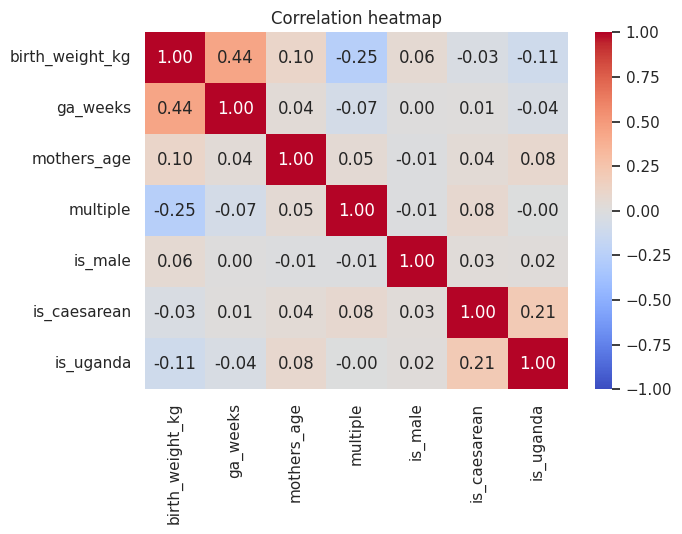

,birth_weight_kg
ga_weeks,0.438368
multiple,-0.254470
is_uganda,-0.106957
mothers_age,0.103758
is_male,0.061920
is_caesarean,-0.034963


In [6]:
# Numeric view of the data for the correlation heatmap (binary flags added for key categoricals)
corr_df = df[["birth_weight_kg", "ga_weeks", "mothers_age", "multiple"]].copy()
corr_df["is_male"] = (df["sex"] == "Male").astype(float).where(df["sex"].isin(["Male", "Female"]))
corr_df["is_caesarean"] = (df["mode_of_delivery"] == "Caesarean_Section").astype(float).where(df["mode_of_delivery"].notna())
corr_df["is_uganda"] = (df["country"] == "Uganda").astype(float)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap"); plt.tight_layout(); plt.show()
corr_df.corr()["birth_weight_kg"].drop("birth_weight_kg").sort_values(key=abs, ascending=False)

**What it shows:** gestational age has the strongest link to birth weight (r ≈ 0.44), followed by plurality (`multiple`, r ≈ -0.25, twins and triplets are lighter) and mother's age (r ≈ 0.10). The other features are weakly correlated, and the predictors are not strongly correlated with each other, so multicollinearity is not a worry.
**Decision:** keep gestational age, plurality and mother's age as core numeric features, and keep the categorical columns because the heatmap cannot capture their effect fully.

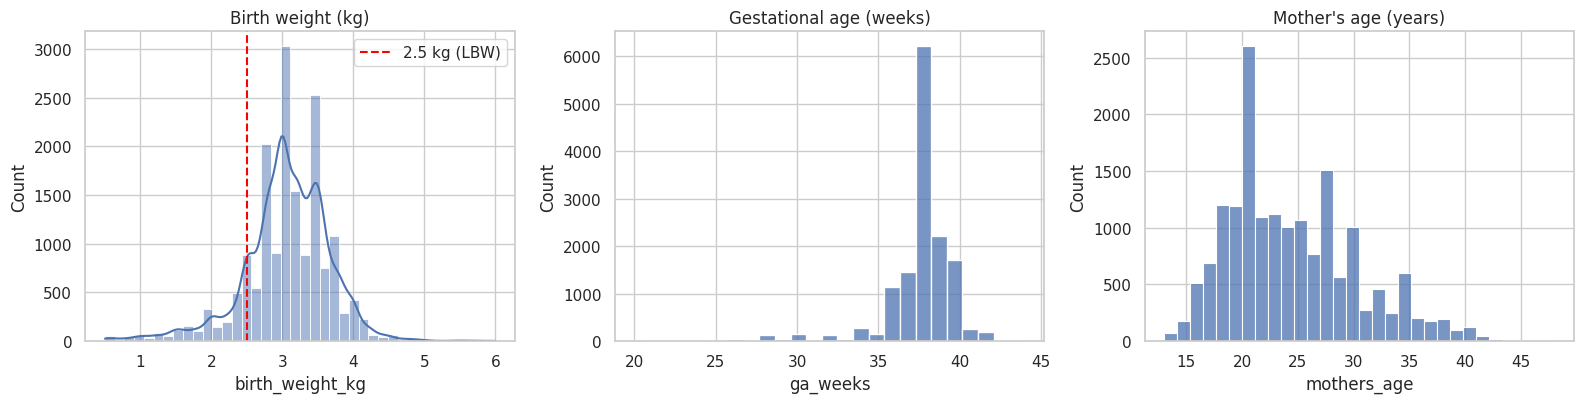

Share of low birth weight (<2.5 kg): 10.9%
Skewness of target: -0.71


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(df[TARGET], bins=40, kde=True, ax=ax[0]); ax[0].axvline(2.5, color="red", ls="--", label="2.5 kg (LBW)"); ax[0].legend()
ax[0].set_title("Birth weight (kg)")
sns.histplot(df["ga_weeks"].dropna(), bins=25, ax=ax[1]); ax[1].set_title("Gestational age (weeks)")
sns.histplot(df["mothers_age"].dropna(), bins=30, ax=ax[2]); ax[2].set_title("Mother's age (years)")
plt.tight_layout(); plt.show()
print("Share of low birth weight (<2.5 kg): %.1f%%" % ((df[TARGET] < 2.5).mean()*100))
print("Skewness of target:", round(df[TARGET].skew(), 2))

**What it shows:** birth weight is roughly bell-shaped around 3.06 kg with a slightly longer tail on the light side; about 10.9% of babies are below 2.5 kg. Gestational age is heavily concentrated at 37-40 weeks with a long tail of preterm births, and mothers are mostly in their late teens to late twenties.
**Decision:** the target is close enough to normal that no log transform is needed. The preterm tail is where the model has most to learn (these are the light babies), so I keep those rows rather than trimming them, and only remove physically impossible weights (outside 0.5-6 kg).

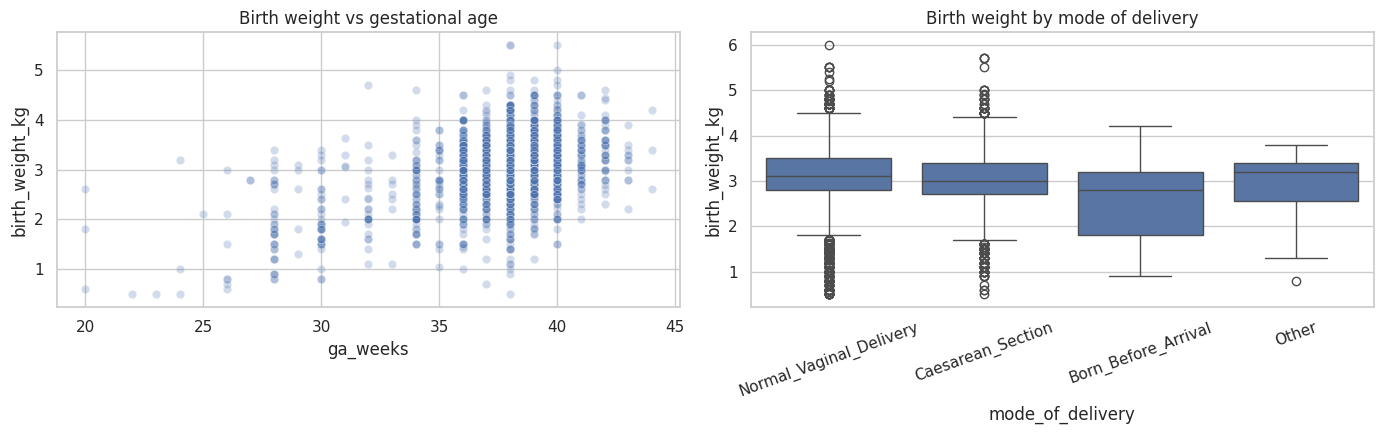

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=df.sample(4000, random_state=1), x="ga_weeks", y=TARGET, alpha=0.25, ax=ax[0])
ax[0].set_title("Birth weight vs gestational age")
sns.boxplot(data=df, x="mode_of_delivery", y=TARGET, ax=ax[1]); ax[1].tick_params(axis="x", rotation=20)
ax[1].set_title("Birth weight by mode of delivery")
plt.tight_layout(); plt.show()

**What it shows:** weight rises with gestational age but not in a perfectly straight line: it climbs steeply between about 28 and 37 weeks and flattens near term, with wide scatter at each week. Delivery mode shows small differences in the median.
**Decision:** a straight line will capture the main trend but miss the curve, so the tree-based models may do better. This is exactly the comparison the four models below will test.

## 4. Feature engineering

**Dropped columns and why**
| Column | Reason |
|---|---|
| `ga (calc)` | Only ~23% filled and contains impossible values (negative and 90+ weeks); the recorded `ga (rec)` is cleaner. |
| `birth_outcome`, `baby_delivery_status`, `baby_discharge_status`, `mother_discharge_status` | These are **outcomes** recorded after birth. Using them would leak information that is not available when we want the prediction. Several are also mostly empty. |
| `eligibility_for_ptbi`, `eligible_for_followup` | Study-eligibility flags that are themselves derived from weight and gestational age (target leakage). |

**Kept features (9):** `ga_weeks`, `mothers_age`, `multiple`, `sex`, `country`, `facility`, `mode_of_delivery`, `viability`, `facility_birth`.

**Categorical to numeric:** one-hot encoding (unseen categories at prediction time are ignored). **Missing values:** median for numeric, most frequent for categorical, fitted on the training set only.

In [9]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Preprocessing: impute -> one-hot encode -> standardize. Everything is fitted on the TRAINING set only.
numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
categorical_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                             ("scale", StandardScaler())])
preprocessor = ColumnTransformer([("num", numeric_pipe, FEATURES_NUM), ("cat", categorical_pipe, FEATURES_CAT)])

Xtr = preprocessor.fit_transform(X_train)   # fit on train only
Xte = preprocessor.transform(X_test)        # test is only transformed
feature_names = preprocessor.get_feature_names_out()
print("Train:", Xtr.shape, "| Test:", Xte.shape, "| Encoded features:", len(feature_names))

Train: (13744, 40) | Test: (3436, 40) | Encoded features: 40


### Which features matter most
A random forest's feature importances give a quick view of what drives birth weight (for features after encoding).

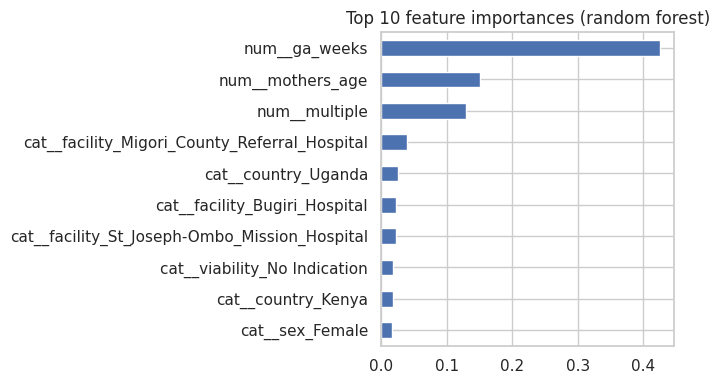

,0
num__ga_weeks,0.426
num__mothers_age,0.151
num__multiple,0.129
cat__facility_Migori_County_Referral_Hospital,0.039
cat__country_Uganda,0.026
cat__facility_Bugiri_Hospital,0.023
cat__facility_St_Joseph-Ombo_Mission_Hospital,0.022
cat__viability_No Indication,0.018
cat__country_Kenya,0.018
cat__sex_Female,0.017


In [10]:
rf_probe = RandomForestRegressor(n_estimators=100, min_samples_leaf=10, random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, y_train)
imp = pd.Series(rf_probe.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)
imp.iloc[::-1].plot.barh(figsize=(7, 4), title="Top 10 feature importances (random forest)"); plt.tight_layout(); plt.show()
imp.round(3)

Gestational age dominates, followed by mother's age (0.15) and plurality (0.13). Facility and delivery-mode dummies contribute a little each. This agrees with the heatmap and confirms that the dropped columns were not needed.

## 5. Train and compare four models
All four use scikit-learn and are scored on the **same test set** with mean squared error (MSE, in kg²).
Hyperparameters are tuned **without touching the test set**: SGD is tuned on a validation split carved out of the training data, and the tree models use 3-fold cross-validation on the training data.

### 5.1 SGDRegressor (linear regression by gradient descent)
`partial_fit` in a loop lets me record train and validation MSE after every epoch. I tune the learning rate (`eta0`), the L2 regularization strength (`alpha`) and the number of epochs.

In [11]:
Xtr_fit, Xval, ytr_fit, yval = train_test_split(Xtr, y_train, test_size=0.2, random_state=RANDOM_STATE)
MAX_EPOCHS = 100

def run_sgd(Xa, ya, Xb, yb, eta0, alpha, epochs, Xc=None, yc=None):
    m = SGDRegressor(penalty="l2", alpha=alpha, learning_rate="constant", eta0=eta0, random_state=RANDOM_STATE)
    tr, ev = [], []
    for _ in range(epochs):
        m.partial_fit(Xa, ya)
        tr.append(mean_squared_error(ya, m.predict(Xa)))
        ev.append(mean_squared_error(yb, m.predict(Xb)))
    return m, tr, ev

rows, curves = [], {}
for eta0 in [0.0001, 0.0005, 0.002, 0.005]:
    for alpha in [1e-5, 1e-2, 1e-1, 1.0]:
        _, tr, ev = run_sgd(Xtr_fit, ytr_fit, Xval, yval, eta0, alpha, MAX_EPOCHS)
        curves[(eta0, alpha)] = ev
        rows.append({"eta0": eta0, "alpha": alpha, "best_epoch": int(np.argmin(ev)) + 1,
                     "val_MSE_best": min(ev), "val_MSE_after_100": ev[-1]})
sgd_grid = pd.DataFrame(rows).sort_values("val_MSE_best").reset_index(drop=True)
display(sgd_grid.round(5))
best = sgd_grid.iloc[0]
BEST_ETA0, BEST_ALPHA, BEST_EPOCHS = best.eta0, best.alpha, int(best.best_epoch)
print(f"Chosen: eta0={BEST_ETA0}, alpha={BEST_ALPHA}, epochs={BEST_EPOCHS}")

,eta0,alpha,best_epoch,val_MSE_best,val_MSE_after_100
0,0.0001,0.00001,15,0.26197,2.619700e-01
1,0.0001,0.01000,17,0.26206,2.620600e-01
2,0.0005,0.00001,21,0.26266,2.626600e-01
3,0.0005,0.01000,23,0.26272,2.627200e-01
4,0.0001,0.10000,16,0.26337,2.633700e-01
5,0.0005,0.10000,3,0.26391,2.639100e-01
6,0.0020,0.10000,4,0.27193,2.719300e-01
7,0.0020,0.01000,5,0.27215,2.721500e-01
8,0.0020,0.00001,15,0.27229,2.722900e-01
9,0.0001,1.00000,34,0.28610,2.861000e-01


Chosen: eta0=0.0001, alpha=1e-05, epochs=15


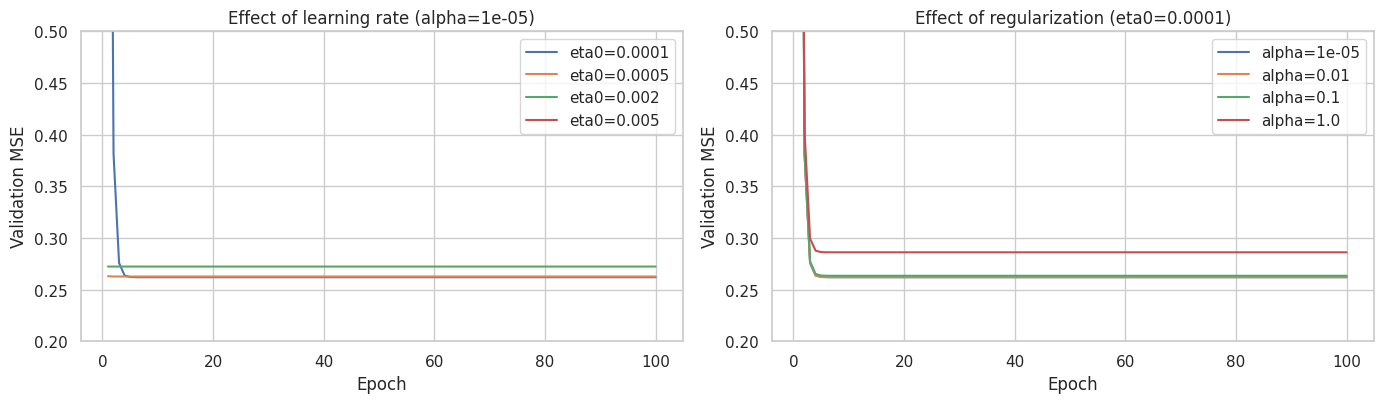

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for (eta0, alpha), ev in curves.items():
    if alpha == BEST_ALPHA: ax[0].plot(range(1, MAX_EPOCHS+1), ev, label=f"eta0={eta0}")
ax[0].set_title(f"Effect of learning rate (alpha={BEST_ALPHA})"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Validation MSE"); ax[0].set_ylim(0.2, 0.5); ax[0].legend()
for (eta0, alpha), ev in curves.items():
    if eta0 == BEST_ETA0: ax[1].plot(range(1, MAX_EPOCHS+1), ev, label=f"alpha={alpha}")
ax[1].set_title(f"Effect of regularization (eta0={BEST_ETA0})"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Validation MSE"); ax[1].set_ylim(0.2, 0.5); ax[1].legend()
plt.tight_layout(); plt.show()

**What tuning showed:** **Learning rate** mattered most. With `eta0` ≥ 0.005 and weak regularization the loss exploded (validation MSE in the hundreds or worse), because the steps overshoot the minimum. `eta0` = 0.002 was stable but noisier and ended higher (≈ 0.272), while `eta0` = 0.0001 gave the lowest validation MSE (≈ 0.262). **Regularization (`alpha`)** was nearly irrelevant between 1e-5 and 1e-2 (same MSE to 3 decimals), slightly worse at 0.1 (≈ 0.263) and clearly worse at 1.0 (≈ 0.286) because the weights are shrunk so hard that the model underfits. This is expected with only 9 features and thousands of rows: there is little variance to regularize. **Epochs:** with a small learning rate the validation loss is essentially flat after about 4 epochs (later changes are in the 4th decimal); the minimum is at epoch 15, so I train for 15 epochs. Note that the curves for `eta0` ≥ 0.005 with weak regularization are off the top of the left plot because they diverged. Chosen: `eta0`=0.0001, `alpha`=1e-5, 15 epochs.

### Loss curve: train vs test MSE per epoch (SGDRegressor)

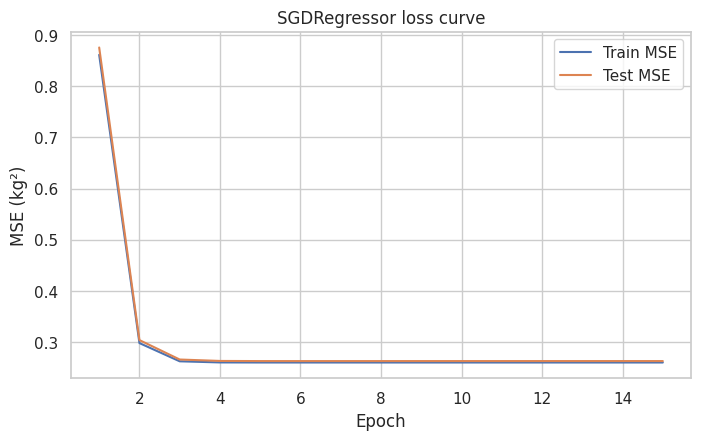

Final train MSE 0.2607 | final test MSE 0.2635


In [13]:
sgd, sgd_train_loss, sgd_test_loss = run_sgd(Xtr, y_train, Xte, y_test, BEST_ETA0, BEST_ALPHA, BEST_EPOCHS)

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, BEST_EPOCHS+1), sgd_train_loss, label="Train MSE")
plt.plot(range(1, BEST_EPOCHS+1), sgd_test_loss, label="Test MSE")
plt.xlabel("Epoch"); plt.ylabel("MSE (kg²)"); plt.title("SGDRegressor loss curve"); plt.legend(); plt.show()
print(f"Final train MSE {sgd_train_loss[-1]:.4f} | final test MSE {sgd_test_loss[-1]:.4f}")

**What it shows:** both curves drop steeply in the first 2-3 epochs and are flat from about epoch 4. Train MSE (0.261) and test MSE (0.264) sit almost on top of each other, so the model is **not overfitting**. The remaining error is a limit of a straight-line model on this data, not a training problem. **Decision:** 15 epochs (the validation minimum); more epochs add nothing.

### 5.2 LinearRegression (closed form), 5.3 Decision tree, 5.4 Random forest

In [14]:
lin = LinearRegression().fit(Xtr, y_train)

dt_search = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                         {"max_depth": [4, 6, 8, 12, None], "min_samples_leaf": [5, 20, 50]},
                         cv=3, scoring="neg_mean_squared_error", n_jobs=-1).fit(Xtr, y_train)
dt = dt_search.best_estimator_
print("Decision tree best params:", dt_search.best_params_)

rf_search = GridSearchCV(RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1),
                         {"max_depth": [8, 12, None], "min_samples_leaf": [5, 10, 20]},
                         cv=3, scoring="neg_mean_squared_error", n_jobs=1).fit(Xtr, y_train)
rf = rf_search.best_estimator_
print("Random forest best params:", rf_search.best_params_)

Decision tree best params: {'max_depth': 12, 'min_samples_leaf': 20}
Random forest best params: {'max_depth': 12, 'min_samples_leaf': 5}


## 6. Comparison table (same test set, MSE)

In [15]:
models = {"SGDRegressor (gradient descent)": sgd, "LinearRegression (closed form)": lin,
          "DecisionTreeRegressor": dt, "RandomForestRegressor": rf}
results = pd.DataFrame([{"Model": n,
                         "Train MSE": mean_squared_error(y_train, m.predict(Xtr)),
                         "Test MSE": mean_squared_error(y_test, m.predict(Xte))} for n, m in models.items()])
results["Test RMSE (g)"] = np.sqrt(results["Test MSE"]) * 1000
results = results.sort_values("Test MSE").reset_index(drop=True)
display(results.round(4))
best_name = results.loc[0, "Model"]
print(f"\nBEST MODEL (lowest test MSE): {best_name}  |  test MSE = {results.loc[0, 'Test MSE']:.4f} kg²")

,Model,Train MSE,Test MSE,Test RMSE (g)
0,RandomForestRegressor,0.2238,0.2552,505.1263
1,LinearRegression (closed form),0.2604,0.2628,512.6121
2,SGDRegressor (gradient descent),0.2607,0.2635,513.2826
3,DecisionTreeRegressor,0.2440,0.2675,517.2360



BEST MODEL (lowest test MSE): RandomForestRegressor  |  test MSE = 0.2552 kg²


### Best model: RandomForestRegressor (test MSE 0.2552 kg², about 505 g RMSE)
**Criterion:** the best model is the one with the **lowest test MSE** on the held-out 20% of deliveries, because that is the best estimate of how it will do on new births.

**Results:** Random forest 0.2552 < closed-form linear regression 0.2628 < SGDRegressor 0.2635 < decision tree 0.2675 (test MSE, kg²).

**How the dataset affected each model:**
- **SGDRegressor and LinearRegression** land within 0.3% of each other: they solve the same least-squares problem, and gradient descent converges to the closed-form answer once the learning rate is small enough. Their train and test errors are close (0.26 vs 0.263), so they underfit slightly: the weight-vs-gestational-age relationship curves, and a line cannot follow it.
- **Decision tree** can follow the curve but is a single high-variance model: train MSE 0.244 vs test 0.2675, so it is the worst on new data even after limiting depth to 12 with at least 20 rows per leaf.
- **Random forest** averages many trees, which keeps their flexibility (non-linear gestational age effect, twin × gestational age interactions, facility effects) while cutting variance. It has the lowest test MSE. Its train MSE (0.224) is lower than its test MSE (0.255), a mild generalization gap that the leaf-size limit keeps in check.

**Why random forest for this problem:** the data has a non-linear main driver, a mix of numeric and categorical columns, and 17% missing gestational age, all of which suit tree ensembles. The gain over the linear models is modest (about 3% lower MSE), which also says the register fields only explain part of the variation in weight (roughly 30%). The forest is the best choice on test error, and linear regression is the fallback if a simpler, explainable model is preferred.

## 7. Scatter plots: before and after the fitted line

Most correlated feature: ga_weeks


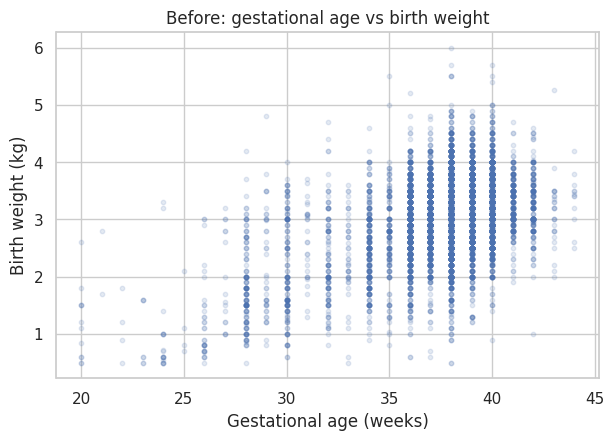

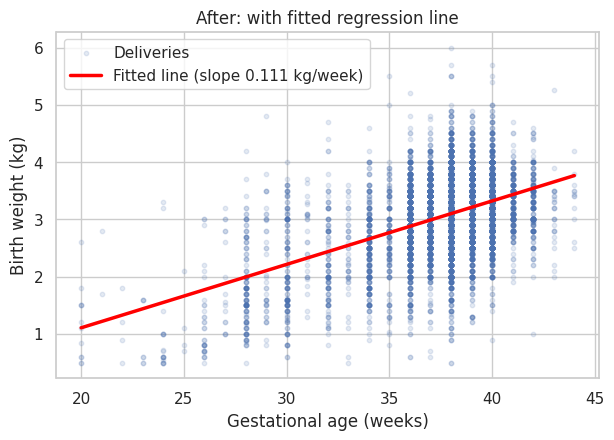

In [16]:
# Feature most correlated with the target
top_feat = corr_df.corr()["birth_weight_kg"].drop("birth_weight_kg").abs().idxmax()
print("Most correlated feature:", top_feat)
sub = df[[top_feat, TARGET]].dropna()

plt.figure(figsize=(7, 4.5))
plt.scatter(sub[top_feat], sub[TARGET], alpha=0.15, s=10)
plt.xlabel("Gestational age (weeks)"); plt.ylabel("Birth weight (kg)"); plt.title("Before: gestational age vs birth weight")
plt.show()

# One-feature linear regression, used for this plot only
line = LinearRegression().fit(sub[[top_feat]], sub[TARGET])
xs = np.linspace(sub[top_feat].min(), sub[top_feat].max(), 100)
plt.figure(figsize=(7, 4.5))
plt.scatter(sub[top_feat], sub[TARGET], alpha=0.15, s=10, label="Deliveries")
plt.plot(xs, line.predict(pd.DataFrame({top_feat: xs})), color="red", lw=2.5, label=f"Fitted line (slope {line.coef_[0]:.3f} kg/week)")
plt.xlabel("Gestational age (weeks)"); plt.ylabel("Birth weight (kg)"); plt.title("After: with fitted regression line"); plt.legend(); plt.show()

The red line shows the average trend: each extra week of gestation adds roughly the slope shown in the legend, in kilograms. The points fan out around it, especially below 37 weeks where the relationship curves, which is why a single straight line cannot match the best model.

## 8. Save the best model with its preprocessing, and predict one row

In [17]:
best_model = models[best_name]
final_pipeline = Pipeline([("preprocess", preprocessor), ("model", best_model)])   # both already fitted on the training set

import os
os.makedirs("../API", exist_ok=True)
MODEL_PATH = "../API/best_model.pkl"
joblib.dump(final_pipeline, MODEL_PATH)
# The tuned model is a tree ensemble if it wins, so /retrain needs the original data to refit on original + new rows
df[FEATURES + [TARGET]].to_csv("../API/training_data.csv", index=False)
print("Saved:", MODEL_PATH, f"({os.path.getsize(MODEL_PATH)/1e6:.1f} MB)")

# Sanity check: the saved pipeline reproduces the test MSE from raw (unprocessed) rows
reloaded = joblib.load(MODEL_PATH)
print("Reloaded test MSE:", round(mean_squared_error(y_test, reloaded.predict(X_test)), 4))

Saved: ../API/best_model.pkl (7.2 MB)
Reloaded test MSE: 0.2552


In [18]:
def predict_one_row(row_index=0, model_path=MODEL_PATH):
    """Load the saved pipeline and predict birth weight for ONE row of the test set."""
    model = joblib.load(model_path)
    row = X_test.iloc[[row_index]]                       # one raw row (a DataFrame with the 9 feature columns)
    predicted = float(model.predict(row)[0])
    actual = float(y_test.iloc[row_index])
    print(row.T.to_string(header=False))
    print(f"\nPredicted birth weight: {predicted:.3f} kg ({predicted*1000:.0f} g)")
    print(f"Actual birth weight:    {actual:.3f} kg ({actual*1000:.0f} g)")
    return predicted

predict_one_row(0)

ga_weeks                             38.0
mothers_age                          27.0
multiple                                1
sex                                  Male
country                            Uganda
facility                  Kamuli_Hospital
mode_of_delivery  Normal_Vaginal_Delivery
viability                   No Indication
facility_birth             Facility birth

Predicted birth weight: 3.172 kg (3172 g)
Actual birth weight:    3.000 kg (3000 g)


3.1719697547046857

### Hand-off to the API (Task 2)
`predict_one_row` shows the exact steps the API reuses: load `best_model.pkl`, build a one-row DataFrame with the 9 raw columns in the order of `FEATURES`, and call `predict`. The model returns kilograms. `training_data.csv` is saved next to the model so `/retrain` can refit on the original data plus the uploaded rows.